# 4. Five issues (extension)

**Examples of:**

- a negotiation on **five issues**: margin, charges, slot, notice and duration;
- an issue where the preferences are **not monotonic**: Bob prefers a short notice to no notice at all;
- options both agents prefer ("free" agreements), and options to trade;
- comparing the Pareto frontier, the Nash package, "splitting the difference" and the agents.

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from charging import *

## 4.1 Two more issues

| Issue | Options | Alice's points | Bob's points |
|---|---|---|---|
| notice (booking in advance) | 0 h, 2 h, 12 h, 24 h, 48 h | 0, 6, 11, 15, 15 | 6, 10, 5, 2, 0 |
| duration of the agreement | 1, 3, 6, 12 months | 7, 10, 6, 0 | 0, 6, 13, 20 |

- **Notice**: Alice wants to plan; Bob wants to charge when he needs it.   
But with **no notice at all**, Bob is never sure the charger will be free when he arrives:   
he prefers to book 2 h before (10 points) rather than not at all (6 points).
- **Duration**: Alice prefers a short trial (3 months is her best: she does not want to renegotiate every month);  
Bob wants a long agreement, to be sure he can charge.

With five issues, both agents have a maximum of 100 points. Reservations are: **40** for Alice, **35** for Bob.

---

**Exercise 1**.
- Alice proposes `{"margin": 0.10, "charges": 6, "slot": "7h-18h", "notice": "24 h", "duration": "3 months"}`.
- Bob proposes `{"margin": 0.02, "charges": 12, "slot": "7h-18h", "notice": "2 h", "duration": "12 months"}`.
- Compute the scores of both proposals for Alice and for Bob.
- Would the other agent accept each proposal (≥ 40 for Alice, ≥ 35 for Bob)?

In [2]:
# Exercise 1: your code here

Alice's proposal: Alice 89, Bob 39
ok for alice
ok for bob
Bob's proposal: Alice 35, Bob 96
unacceptable for alice
ok for bob


> **Reading.**
> - Alice's proposal gives her 89 points and Bob 39, just above his reservation (35): he could accept, but he gains very little.
> - Bob's proposal gives him 96 points, but Alice only 35 (< 40): she refuses.
> - Both already propose the **day slot**: on this issue they agree.
> - Each one proposes what is good for itself: the agreement lies in between... but not by splitting each issue.

---

## 4.2 Pareto, Nash and splitting the difference

**Exercise 2**.
- Build all the packages on `ISSUES_5`.  
How many are there?
- Find the Nash package: maximise $(s_A - 40)(s_B - 35)$ among the acceptable packages, and print it.
- Draw all the packages with `show_packages`   
and mark: the Nash package, the "split the difference" package
`{"margin": 0.08, "charges": 8, "slot": "22h-7h", "notice": "12 h", "duration": "6 months"}`.

In [4]:
# Exercise 2: your code here

2400 packages, 1558 acceptable for both
Nash package: {'margin': 0.08, 'charges': 8, 'slot': '7h-18h', 'notice': '24 h', 'duration': '12 months'} (69, 66)
split the difference: (56, 59)


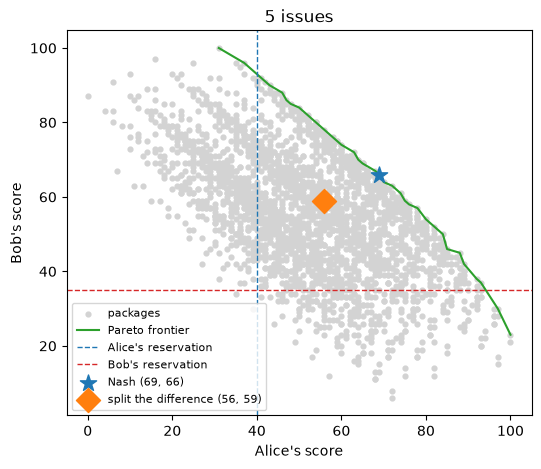

In [ ]:

middle5 = {"margin": 0.08, "charges": 8, "slot": "22h-7h", "notice": "12 h", "duration": "6 months"}
print(len(packages5), "packages,", len(acceptable5), "acceptable for both")
print("Nash package:", nash5, (score(nash5, ALICE_SHEET), score(nash5, BOB_SHEET)))
print("split the difference:", (score(middle5, ALICE_SHEET), score(middle5, BOB_SHEET)))
show_packages(packages5, ALICE_RESERVATION_5, BOB_RESERVATION_5,
              marked={"Nash": nash5, "split the difference": middle5}, title="5 issues");

> **Reading.**
> - 2400 packages.  
> Nash package: **margin 0.08 (price 0.28 EUR/kWh), 8 charges, day slot, 24 h notice, 12 months**: scores (69, 66).
> - Splitting the difference gives (56, 59): Alice loses 13 points, Bob 7.
> - The Nash package trades again: both get the day slot; 
>   - Alice gets the notice she wants (24 h); 
>   - Bob gets the long agreement (12 months).
> - Humans often split the difference issue by issue: it is easy to explain, but it wastes value.

---

## 4.3 Options both agents prefer

**Exercise 3**.
- For each issue, compare the options **two by two**:   
list the pairs of options $(o_1, o_2)$ where **both** agents give more points to $o_1$ than to $o_2$.
- Which issues are fully opposed (no such pair)?

In [6]:
# Exercise 3: your code here

In [22]:
#little help:
issue0 = ISSUES_5[0]
print(f"criteria : {issue0}")
options = list(ALICE_SHEET[issue0])
print(f"possible options for '{issue0}' = {options}")
print("value for first option {options[0]}:")
print(f"for Alice, {ALICE_SHEET[issue0][options[0]]}", end="\t")
print(f"for Bob, {BOB_SHEET[issue0][options[0]]}", end="\t")

criteria : margin
possible options for 'margin' = [0.0, 0.02, 0.04, 0.06, 0.08, 0.1, 0.12, 0.14]
value for first option {options[0]}:
for Alice, 0	for Bob, 30	

margin   : fully opposed
charges  : fully opposed
slot     : [('7h-18h', '18h-22h'), ('7h-18h', '22h-7h'), ('22h-7h', '18h-22h')]
notice   : [('2 h', '0 h')]
duration : [('3 months', '1 month')]


> **Reading.**
> - **Margin** and **charges** are fully opposed: what one gains, the other loses.
> - **Slot**: not opposed at all: both prefer the day to the night, and the night to the evening.
> - **Notice**: both prefer 2 h to no notice ("0 h"): a booking system helps both.
> - **Duration**: both prefer 3 months to 1 month.
> - Such options are "free" agreements:  
> an agent that accepts the night slot, "0 h" or "1 month" to look generous gives nothing to the other.

---

## 4.4 The agents on five issues

**Exercise 4**.
- Run the pairs blind/blind and trade-off/trade-off on the five issues:  
use `negotiate(alice, bob, ISSUES_5, res_a=ALICE_RESERVATION_5, res_b=BOB_RESERVATION_5)`   
and strategies built with `ISSUES_5`.
- Print the deals and draw the trade-off negotiation. 
- Compare with the Nash package.

In [8]:
# Exercise 4: your code here

blind    : round 13, scores (66, 56), {'margin': 0.0, 'charges': 4, 'slot': '7h-18h', 'notice': '12 h', 'duration': '3 months'}
trade-off: round 10, scores (69, 66), {'margin': 0.08, 'charges': 8, 'slot': '7h-18h', 'notice': '24 h', 'duration': '12 months'}


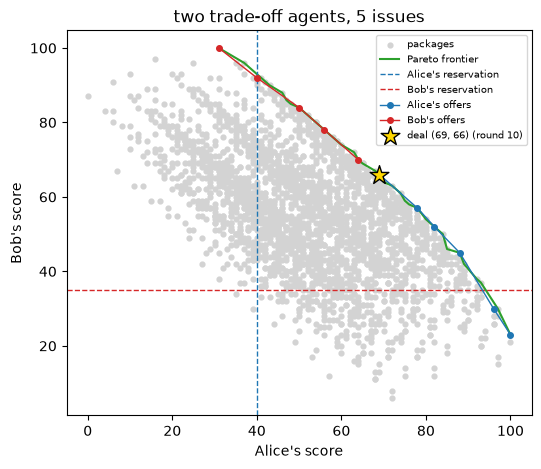

In [ ]:

show_negotiation(res, ALICE_RESERVATION_5, BOB_RESERVATION_5, title="two trade-off agents, 5 issues");

> **Reading.**
> - Two blind agents agree on (66, 56): no margin (Bob pays 0.20 EUR/kWh) but only **4 charges** a month: Bob pays little, but cannot charge enough!
> - Two trade-off agents agree on **(69, 66)** at round 10: this is the **Nash package** again.

---

**Exercise 5** *(explore)*.
- Write your **own** strategy (a plain function, no class needed), for example:
  - a trade-off agent that never proposes the options both agents dislike ("0 h", "1 month", "18h-22h");
  - an agent that starts Boulware and becomes trade-off after half of the rounds;
  - an agent that guesses which issues matter to the other by looking at what the other never changes in its offers.
- Make it negotiate against `blind` and `trade_off`, on 5 issues. Does it reach better agreements?
- **Question**: if Alice knew Bob's sheet, which package would she propose at the first round? Why is this not realistic?

In [10]:
# Exercise 5: your code here

In [ ]:
#EXAMPLE OF SOLUTION 

def no_waste(r, T, mine, theirs, sheet, issues, reservation, beta):
#TODO

for name, strategy in (("blind", blind), ("trade-off", trade_off), ("no-waste", no_waste)):
    res = negotiate(agent5(no_waste, ALICE_SHEET, ALICE_RESERVATION_5), agent5(strategy, BOB_SHEET, BOB_RESERVATION_5),
                    ISSUES_5, res_a=ALICE_RESERVATION_5, res_b=BOB_RESERVATION_5)
    print(f"no-waste Alice vs {name:9s} Bob: round {res['round']}, scores {res['scores']}")

no-waste Alice vs blind     Bob: round 12, scores (66, 59)
no-waste Alice vs trade-off Bob: round 10, scores (69, 66)
no-waste Alice vs no-waste  Bob: round 10, scores (69, 66)


> **Reading.**
> - Here the no-waste Alice does exactly as well as a trade-off Alice: (66, 59) against a blind Bob, the Nash package against a trade-off Bob.
> Removing the options both dislike changes nothing:  
> the offers close to the other's offers never contain them.
> - With full information, Alice could propose the Nash package (or a package on the frontier that suits her) at once.
> - But each agent keeps its sheet private, and has an interest in **hiding** what matters to it
> (if Bob says "the duration is crucial for me", Alice can ask a lot in exchange).
> - This is why negotiating agents need strategies that **learn from the offers**.

---

## Key points

| Idea | In the charger sharing |
|---|---|
| non-monotonic preference | Bob prefers 2 h of notice to no notice |
| opposed issues | margin, charges |
| options both prefer | the day slot (then the night), 2 h rather than 0 h, 3 months rather than 1 month |
| Nash package (5 issues) | margin 0.08, 8 charges, 7h-18h, 24 h, 12 months: (69, 66) |
| trade-off agents | (69, 66), the Nash package; blind agents (66, 56) with too few charges for Bob |